# Chapitre 11 - Cours 5 : traiter les flux, à quoi cela sert

Les cours 1 à 4 ont montré d'où viennent les flux (activité des utilisateurs, capteurs,
écritures dans une base) et comment ils sont transportés (messagerie directe, courtiers,
journaux). Reste à savoir **ce que l'on en fait**. Ce notebook couvre le début de la
section *Processing Streams* et la sous-section *Uses of Stream Processing* (*Complex
event processing*, *Stream analytics*, *Maintaining materialized views*, *Search on
streams*, *Message passing and RPC*). Le temps, les jointures et la tolérance aux
pannes sont l'objet des cours 6 et 7.

**Plan.**

1. Trois façons d'utiliser un flux ; l'opérateur de flux.
2. La détection d'événements complexes (CEP).
3. L'analytique sur flux et les algorithmes probabilistes.
4. Maintenir des vues matérialisées.
5. La recherche sur flux.
6. Flux, acteurs et RPC.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Trois façons d'utiliser un flux (section *Processing Streams*)

Une fois un flux disponible, on peut :

1. **écrire** ses événements dans une base, un cache, un index, d'où d'autres clients les
   interrogeront : c'est la synchronisation des systèmes du cours 3, l'équivalent en flux
   des sorties d'un traitement par lots ;
2. **pousser** les événements vers des humains : alertes par courriel, notifications,
   tableau de bord temps réel ;
3. **transformer** un ou plusieurs flux d'entrée en un ou plusieurs flux de sortie, par
   une chaîne d'étapes qui aboutit finalement à 1 ou 2.

Le code qui fait 3 s'appelle un **opérateur** ou un **job**. Il ressemble beaucoup aux
processus Unix et aux jobs MapReduce du chapitre 10 : il lit ses entrées en
lecture seule et écrit ses sorties ailleurs, en ajout seul ; le partitionnement, la
parallélisation, les transformations et filtres élémentaires fonctionnent de la même
façon. La différence cruciale : **un flux ne se termine jamais**. On ne peut donc pas
trier l'entrée (et les jointures par tri-fusion sont exclues), et la tolérance aux pannes
change : on relance une tâche par lots de quelques minutes depuis le début, pas un job de
flux qui tourne depuis des années.

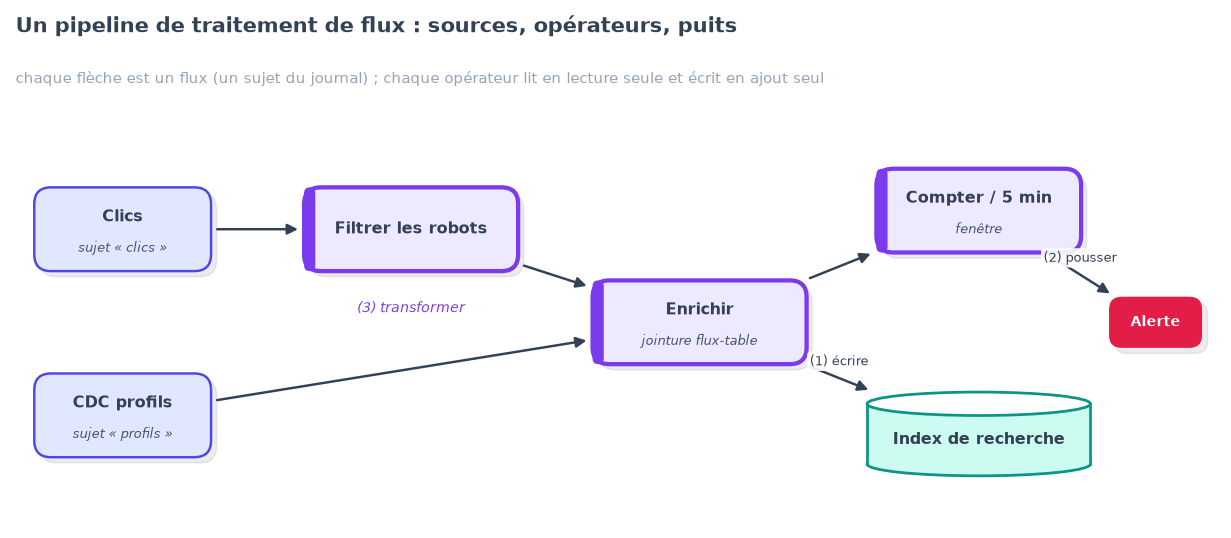

In [2]:
d = Diagram(13, 4.6, title="Un pipeline de traitement de flux : sources, opérateurs, puits",
            subtitle="chaque flèche est un flux (un sujet du journal) ; chaque opérateur lit en lecture seule et écrit en ajout seul")
d.box("s1", 1.2, 3.2, "Clics", sub="sujet « clics »", color=INDIGO, w=1.9)
d.box("s2", 1.2, 1.2, "CDC profils", sub="sujet « profils »", color=INDIGO, w=1.9)
d.box("o1", 4.3, 3.2, "Filtrer les robots", color=VIOLET, kind="model", w=2.3)
d.box("o2", 7.4, 2.2, "Enrichir", sub="jointure flux-table", color=VIOLET, kind="model", w=2.3)
d.box("o3", 10.4, 3.4, "Compter / 5 min", sub="fenêtre", color=VIOLET, kind="model", w=2.2)
d.box("k1", 10.4, 1.0, "Index de recherche", color=TEAL, kind="db", w=2.4, h=0.9)
d.box("k2", 12.3, 2.2, "Alerte", color=ROSE, kind="tag", w=1.0, h=0.55, fontsize=9)
d.arrow("s1", "o1"); d.arrow("o1", "o2"); d.arrow("s2", "o2")
d.arrow("o2", "o3"); d.arrow("o2", "k1", "(1) écrire")
d.arrow("o3", "k2", "(2) pousser")
d.note(4.3, 2.35, "(3) transformer", color=VIOLET)
d.show()

Historiquement, le traitement de flux sert surtout à la **surveillance** : détecter un
changement de comportement d'une carte bancaire volée, exécuter des ordres selon les
variations de prix d'un marché, repérer une machine défaillante dans une usine, ou, dans
le militaire et le renseignement, donner l'alarme au moindre signe d'attaque. D'autres
usages sont apparus ensuite ; les sections suivantes les passent en revue.

> **À retenir.** Un flux sert à alimenter un stockage, à notifier des humains, ou à
> produire d'autres flux par des opérateurs. Comme un job par lots, mais sans fin : ni tri
> de l'entrée, ni reprise « depuis le début ».